In [3]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing import image_dataset_from_directory

from tensorflow.keras.applications import (
    VGG16,
    ResNet50,
    DenseNet121,
    EfficientNetB0,
    MobileNetV2
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [4]:
TRAIN_DIR = "data/Training"
TEST_DIR = "data/Testing"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

EPOCHS = 20

print("Train path:", TRAIN_DIR)
print("Test path:", TEST_DIR)

Train path: data/Training
Test path: data/Testing


In [5]:
train_ds = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

test_ds = image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


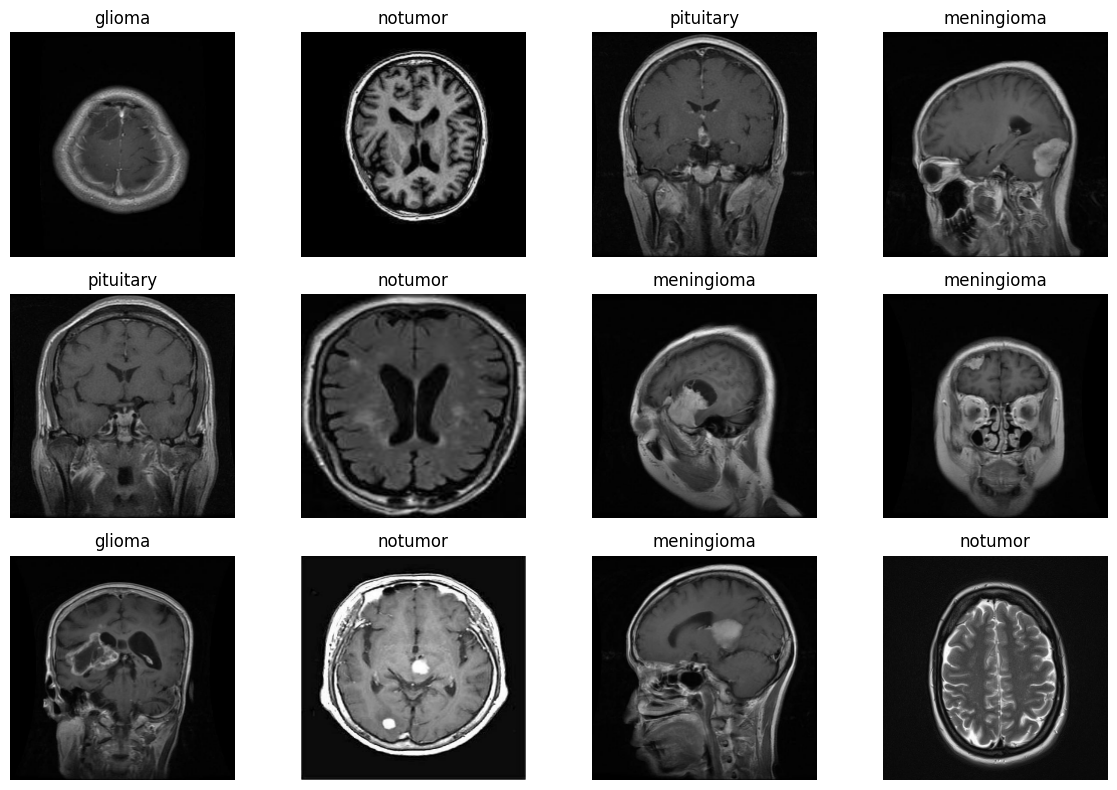

In [6]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
from collections import Counter

train_counts = Counter()

for _, labels in train_ds:
    train_counts.update(labels.numpy())

test_counts = Counter()

for _, labels in test_ds:
    test_counts.update(labels.numpy())

print("Training distribution:")
for i, name in enumerate(class_names):
    print(name, ":", train_counts[i])

print("\nTesting distribution:")
for i, name in enumerate(class_names):
    print(name, ":", test_counts[i])

Training distribution:
glioma : 1400
meningioma : 1400
notumor : 1400
pituitary : 1400

Testing distribution:
glioma : 400
meningioma : 400
notumor : 400
pituitary : 400


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Data Augmentation
## Brain MRI images should not be augmented as aggressively as normal photographs.
### because they can produce medically unrealistic images or alter clinically relevant structures.

In [9]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="data_augmentation")

# Baseline CNN

In [56]:
def create_custom_cnn(num_classes):

    model = models.Sequential([
        
        layers.Input(shape=(224, 224, 3)),

        data_augmentation,

        layers.Rescaling(1./255),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(256, (3, 3), activation="relu"),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(num_classes, activation="softmax")
    ])

    return model

In [57]:
custom_cnn = create_custom_cnn(len(class_names))

custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

custom_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [58]:
def get_callbacks(model_name):

    os.makedirs("models", exist_ok=True)

    return [
        EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7
        ),

        ModelCheckpoint(
            f"models/{model_name}.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ]

In [59]:
# start_time = time.time()

# history_custom = custom_cnn.fit(
#     train_ds,
#     validation_data=test_ds,
#     epochs=EPOCHS,
#     callbacks=get_callbacks("custom_cnn")
# )

# custom_training_time = time.time() - start_time

# print(
#     f"Training time: {custom_training_time / 60:.2f} minutes"
# )

In [60]:
train_ds = image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.


# General Transfer Learning Model

In [61]:
def create_transfer_model(base_model, num_classes):

    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))

    x = data_augmentation(inputs)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.BatchNormalization()(x)

    x = layers.Dense(256, activation="relu")(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = Model(inputs, outputs)

    return model

# VGG16

In [62]:
vgg_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_model = create_transfer_model(
    vgg_base,
    len(class_names)
)

In [63]:
vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Stage1: vgg16_training

In [64]:
# start_time = time.time()

# history_vgg16 = vgg16_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=EPOCHS,
#     callbacks=get_callbacks("vgg16")
# )

# vgg16_time = time.time() - start_time

## stage2: vgg16_fine_tuning

In [65]:
vgg_base.trainable = True

# Freeze the earlier layers
for layer in vgg_base.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in vgg_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very small learning rate
vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"]
)

start_finetune = time.time()

history_vgg16_finetune = vgg16_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=get_callbacks("vgg16_finetune")
)

finetune_time = time.time() - start_finetune

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 1823s 13s/step - accuracy: 0.6487 - loss: 0.9463 - val_accuracy: 0.8589 - val_loss: 0.3847 - learning_rate: 1.0000e-05
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 1737s 12s/step - accuracy: 0.8335 - loss: 0.4591 - val_accuracy: 0.8670 - val_loss: 0.3582 - learning_rate: 1.0000e-05
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 1717s 12s/step - accuracy: 0.8797 - loss: 0.3386 - val_accuracy: 0.9045 - val_loss: 0.2730 - learning_rate: 1.0000e-05
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 1803s 13s/step - accuracy: 0.9096 - loss: 0.2640 - val_accuracy: 0.8830 - val_loss: 0.3308 - learning_rate: 1.0000e-05
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 1811s 13s/step - accuracy: 0.9232 - loss: 0.2203 - val_accuracy: 0.9384 - val_loss: 0.1850 - learning_rate: 1.0000e-05
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 1850s 13s/step - accuracy: 0.9391 - loss: 0.1825 - val_accuracy: 0.9000 - val_loss: 0.2683 - learning_rate: 1.0000e-05
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 2907s 

# ResNet50

In [66]:
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

resnet_model = create_transfer_model(
    resnet_base,
    len(class_names)
)

In [ ]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## stage1: resnet50_training

In [68]:
# start_time = time.time()

# history_resnet = resnet_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=EPOCHS,
#     callbacks=get_callbacks("resnet50")
# )

# resnet_time = time.time() - start_time

## stage2: resnet50_fine-tuning

In [69]:
# resnet_base.trainable = True

# # Freeze the earlier layers
# for layer in resnet_base.layers[:-30]:
#     layer.trainable = False

# # Keep BatchNormalization layers frozen
# for layer in resnet_base.layers:
#     if isinstance(layer, layers.BatchNormalization):
#         layer.trainable = False

# # Recompile with a very small learning rate
# resnet_model.compile(
#     optimizer=tf.keras.optimizers.Adam(
#         learning_rate=1e-5
#     ),
#     loss="sparse_categorical_crossentropy",
#     metrics=["accuracy"]
# )

# start_finetune = time.time()

# history_resnet_finetune = resnet_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=10,
#     callbacks=get_callbacks("resnet50_finetune")
# )

# finetune_time = time.time() - start_finetune

# DenseNet121

In [70]:
densenet_base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

densenet_model = create_transfer_model(
    densenet_base,
    len(class_names)
)

In [71]:
densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [72]:
# start_time = time.time()

# history_densenet = densenet_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=EPOCHS,
#     callbacks=get_callbacks("densenet121")
# )

# densenet_time = time.time() - start_time

# MobileNetV2

In [73]:
mobilenet_base = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenet_model = create_transfer_model(
    mobilenet_base,
    len(class_names)
)

In [74]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [75]:
# start_time = time.time()

# history_mobilenet = mobilenet_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=EPOCHS,
#     callbacks=get_callbacks("mobilenetv2")
# )

# mobilenet_time = time.time() - start_time

# EfficientNetB0

In [76]:
efficientnet_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnet_model = create_transfer_model(
    efficientnet_base,
    len(class_names)
)

In [77]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## stage1: efficientnetb0_training

In [78]:
# start_time = time.time()

# history_efficientnet = efficientnet_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=EPOCHS,
#     callbacks=get_callbacks("efficientnetb0")
# )

# efficientnet_time = time.time() - start_time

## stage2: efficientnetb0_fine-tuning

In [103]:
efficientnet_base.trainable = True

for layer in efficientnet_base.layers[:-10]:
    layer.trainable = False

for layer in efficientnet_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_efficientnet_ft10 = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=get_callbacks("efficientnetb0_ft10")
)

Epoch 1/10


140/140 ━━━━━━━━━━━━━━━━━━━━ 125s 828ms/step - accuracy: 0.8333 - loss: 0.4419 - val_accuracy: 0.8830 - val_loss: 0.3390 - learning_rate: 5.0000e-06
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 111s 796ms/step - accuracy: 0.8402 - loss: 0.4245 - val_accuracy: 0.8830 - val_loss: 0.3347 - learning_rate: 5.0000e-06
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 114s 814ms/step - accuracy: 0.8482 - loss: 0.4130 - val_accuracy: 0.8830 - val_loss: 0.3331 - learning_rate: 5.0000e-06
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 111s 795ms/step - accuracy: 0.8516 - loss: 0.4131 - val_accuracy: 0.8839 - val_loss: 0.3268 - learning_rate: 5.0000e-06
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 112s 801ms/step - accuracy: 0.8547 - loss: 0.3913 - val_accuracy: 0.8866 - val_loss: 0.3228 - learning_rate: 5.0000e-06
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 112s 799ms/step - accuracy: 0.8560 - loss: 0.4064 - val_accuracy: 0.8857 - val_loss: 0.3233 - learning_rate: 5.0000e-06
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 114s 813ms/

# Plot Training Curves

In [80]:
def plot_history(history, model_name):

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)

    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])

    plt.title(f"{model_name} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.legend(["Training", "Validation"])

    plt.subplot(1, 2, 2)

    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])

    plt.title(f"{model_name} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.legend(["Training", "Validation"])

    plt.tight_layout()
    plt.show()

In [81]:
# plot_history(history_custom, "CustomNet")

In [82]:
# plot_history(history_densenet, "DenseNet121")

In [83]:
# plot_history(history_efficientnet, "EfficientNetB0")

In [84]:
# plot_history(history_mobilenet, "MobileNetV2")

In [85]:
# plot_history(history_resnet, "ResNet50")

In [86]:
# plot_history(history_vgg16, "VGG16")

In [104]:
def evaluate_model(model, test_ds, class_names):

    y_true = []
    y_pred = []
    y_prob = []

    for images, labels in test_ds:

        predictions = model.predict(
            images,
            verbose=0
        )

        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(predictions, axis=1))
        y_prob.extend(predictions)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    try:
        auc = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="weighted"
        )
    except:
        auc = np.nan

    print("\nClassification Report")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auc": auc,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }

In [ ]:
results = {}

# custom_cnn = tf.keras.models.load_model(
#     "models/custom_cnn.keras"
# )
# results["Custom CNN"] = evaluate_model(
#     custom_cnn,
#     test_ds,
#     class_names
# )

vgg16_model = tf.keras.models.load_model(
    "models/vgg16_finetune.keras"
)
results["VGG16"] = evaluate_model(
    vgg16_model,
    test_ds,
    class_names
)

resnet_model = tf.keras.models.load_model(
    "models/resnet50_finetune.keras"
)
results["ResNet50"] = evaluate_model(
    resnet_model,
    test_ds,
    class_names
)

# densenet_model = tf.keras.models.load_model(
#     "models/densenet121.keras"
# )
# results["DenseNet121"] = evaluate_model(
#     densenet_model,
#     test_ds,
#     class_names
# )

# efficientnet_model = tf.keras.models.load_model(
#     "models/efficientnetb0_ft10.keras"
# )
# results["EfficientNetB0"] = evaluate_model(
#     efficientnet_model,
#     test_ds,
#     class_names
# )

# mobilenet_model = tf.keras.models.load_model(
#     "models/mobilenetv2.keras"
# )
# results["MobileNetV2"] = evaluate_model(
#     mobilenet_model,
#     test_ds,
#     class_names
# )


Classification Report
              precision    recall  f1-score   support

      glioma       0.97      0.77      0.85       400
  meningioma       0.86      0.83      0.85       400
     notumor       0.89      0.99      0.94       400
   pituitary       0.88      0.99      0.93       400

    accuracy                           0.90      1600
   macro avg       0.90      0.90      0.89      1600
weighted avg       0.90      0.90      0.89      1600


Classification Report
              precision    recall  f1-score   support

      glioma       0.96      0.78      0.86       400
  meningioma       0.85      0.89      0.87       400
     notumor       0.94      1.00      0.97       400
   pituitary       0.93      0.99      0.96       400

    accuracy                           0.92      1600
   macro avg       0.92      0.92      0.92      1600
weighted avg       0.92      0.92      0.92      1600


Classification Report
              precision    recall  f1-score   support

      

In [108]:
comparison = []

for model_name, result in results.items():

    comparison.append({
        "Model": model_name,
        "Accuracy": result["accuracy"],
        "Precision": result["precision"],
        "Recall": result["recall"],
        "F1 Score": result["f1"],
        "AUC": result["auc"]
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,AUC
1,ResNet50,0.917500,0.919938,0.917500,0.915721,0.982558
0,VGG16,0.896250,0.900136,0.896250,0.893647,0.982201
2,EfficientNetB0,0.825625,0.830461,0.825625,0.818350,0.963212


In [109]:
def plot_confusion_matrix(result, model_name, class_names):

    cm = confusion_matrix(
        result["y_true"],
        result["y_pred"]
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{model_name} Confusion Matrix")

    plt.show()

In [91]:
# plot_confusion_matrix(
#     results["DenseNet121"],
#     "DenseNet121",
#     class_names
# )

In [92]:
# plot_confusion_matrix(
#     results["MobileNetV2"],
#     "MobileNetV2",
#     class_names
# )

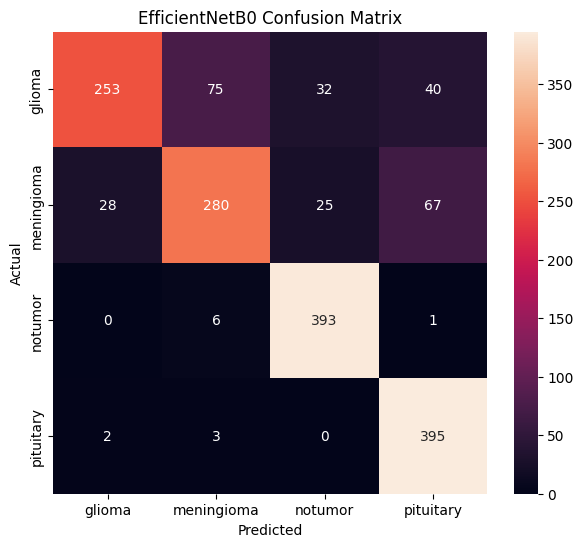

In [ ]:
# plot_confusion_matrix(
#     results["EfficientNetB0"],
#     "EfficientNetB0",
#     class_names
)

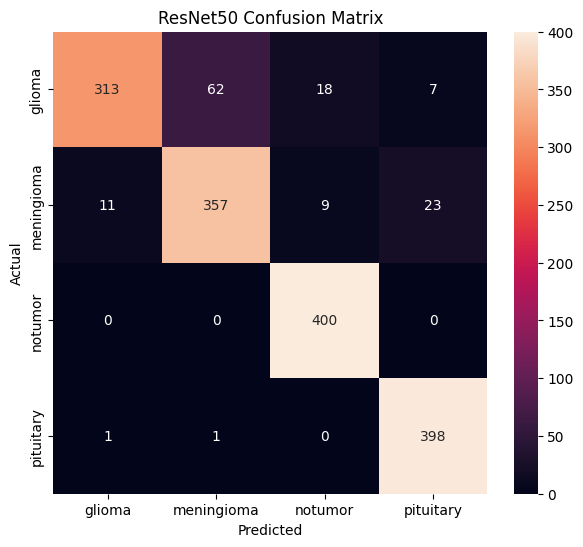

In [111]:
plot_confusion_matrix(
    results["ResNet50"],
    "ResNet50",
    class_names
)

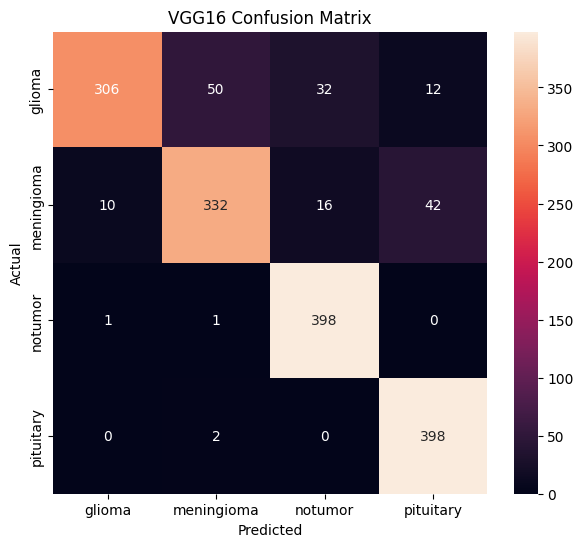

In [112]:
plot_confusion_matrix(
    results["VGG16"],
    "VGG16",
    class_names
)

In [96]:
# plot_confusion_matrix(
#     results["Custom CNN"],
#     "Custom CNN",
#     class_names
# )

In [97]:
model_objects = {
    "Custom CNN": custom_cnn,
    "VGG16": vgg16_model,
    "ResNet50": resnet_model,
    "DenseNet121": densenet_model,
    "EfficientNetB0": efficientnet_model,
    "MobileNetV2": mobilenet_model
}

for name, model in model_objects.items():

    print(
        f"{name}: "
        f"{model.count_params():,} parameters"
    )

Custom CNN: 421,828 parameters
VGG16: 14,849,092 parameters
ResNet50: 24,121,476 parameters
DenseNet121: 7,305,028 parameters
EfficientNetB0: 4,383,655 parameters
MobileNetV2: 2,592,068 parameters


# Solving Code Issues

In [98]:
# import tensorflow as tf
# import numpy as np
# from sklearn.metrics import classification_report

# # 1. Load model
# model = tf.keras.models.load_model("models/mobilenetv2.keras")

# # 2. Load test dataset
# test_ds = tf.keras.utils.image_dataset_from_directory(
#     "data/Testing",
#     image_size=(224, 224),
#     batch_size=32,
#     shuffle=False
# )

# class_names = test_ds.class_names

# # 3. Get predictions
# y_true = []
# y_pred = []

# for images, labels in test_ds:
#     predictions = model.predict(images, verbose=0)

#     y_true.extend(labels.numpy())
#     y_pred.extend(np.argmax(predictions, axis=1))

# # 4. Classification report
# print("MobileNetV2 Classification Report")
# print("----------------------------------")

# print(classification_report(
#     y_true,
#     y_pred,
#     target_names=class_names,
#     digits=4
# ))

In [99]:
# # Check MobileNetV2 predictions directly

# images, labels = next(iter(test_ds))

# predictions = mobilenet_model.predict(images, verbose=0)

# print("True labels:")
# print(labels.numpy()[:20])

# print("\nPredicted labels:")
# print(np.argmax(predictions, axis=1)[:20])

# print("\nPrediction probabilities:")
# print(predictions[:3])

In [100]:
# test_ds = tf.keras.utils.image_dataset_from_directory(
#     "data/Testing",
#     image_size=(224, 224),
#     batch_size=32,
#     shuffle=False
# )

# class_names = test_ds.class_names

# print(class_names)

In [101]:
# print("========== MOBILENET CHECK ==========")

# print("Classes:", class_names)
# print("Output shape:", mobilenet_model.output_shape)
# print("Parameters:", mobilenet_model.count_params())

# images, labels = next(iter(test_ds))

# predictions = mobilenet_model.predict(images, verbose=0)

# print("True:", labels.numpy()[:20])
# print("Pred:", np.argmax(predictions, axis=1)[:20])

# print("=====================================")

# results["MobileNetV2"] = evaluate_model(
#     mobilenet_model,
#     test_ds,
#     class_names
# )

In [102]:
# print("MobileNet model:")
# print(mobilenet_model.summary())

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

import time


# ============================================================
# FINAL EVALUATION FUNCTION
# ============================================================

def ultimate_evaluate(model, test_ds, class_names, model_name):

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    y_true = []
    y_pred = []
    y_prob = []

    total_images = 0
    total_inference_time = 0

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    for images, labels in test_ds:

        start = time.time()

        predictions = model.predict(
            images,
            verbose=0
        )

        end = time.time()

        total_inference_time += (end - start)
        total_images += images.shape[0]

        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(predictions, axis=1))
        y_prob.extend(predictions)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    # --------------------------------------------------------
    # Basic metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    macro_precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    weighted_recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------

    try:

        roc_auc = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro"
        )

    except Exception as e:

        print("ROC-AUC could not be calculated:", e)
        roc_auc = np.nan

    # --------------------------------------------------------
    # Inference
    # --------------------------------------------------------

    inference_per_image = (
        total_inference_time / total_images
    )

    # --------------------------------------------------------
    # Confidence
    # --------------------------------------------------------

    confidence = np.max(y_prob, axis=1)
    mean_confidence = np.mean(confidence)

    # --------------------------------------------------------
    # Parameters
    # --------------------------------------------------------

    parameters = model.count_params()

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\nClassification Report")
    print("-" * 70)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Specificity for each class
    # --------------------------------------------------------

    specificity = []

    for i in range(len(class_names)):

        TP = cm[i, i]

        FN = np.sum(cm[i, :]) - TP

        FP = np.sum(cm[:, i]) - TP

        TN = np.sum(cm) - (TP + FN + FP)

        spec = TN / (TN + FP) if (TN + FP) > 0 else 0

        specificity.append(spec)

    # --------------------------------------------------------
    # Print final metrics
    # --------------------------------------------------------

    print("Overall Metrics")
    print("-" * 70)

    print(f"Accuracy              : {accuracy:.4f}")
    print(f"Macro Precision       : {macro_precision:.4f}")
    print(f"Macro Recall          : {macro_recall:.4f}")
    print(f"Macro F1              : {macro_f1:.4f}")
    print(f"Weighted Precision    : {weighted_precision:.4f}")
    print(f"Weighted Recall       : {weighted_recall:.4f}")
    print(f"Weighted F1           : {weighted_f1:.4f}")
    print(f"ROC-AUC               : {roc_auc:.4f}")
    print(f"Parameters             : {parameters:,}")
    print(f"Inference/image        : {inference_per_image:.6f} sec")
    print(f"Mean Confidence        : {mean_confidence:.4f}")

    print("\nSpecificity")
    print("-" * 70)

    for name, spec in zip(class_names, specificity):

        print(
            f"{name:15s}: {spec:.4f}"
        )

    # --------------------------------------------------------
    # Return everything
    # --------------------------------------------------------

    return {

        "Model": model_name,

        "Accuracy": accuracy,

        "Macro Precision": macro_precision,

        "Macro Recall": macro_recall,

        "Macro F1": macro_f1,

        "Weighted Precision": weighted_precision,

        "Weighted Recall": weighted_recall,

        "Weighted F1": weighted_f1,

        "ROC-AUC": roc_auc,

        "Parameters": parameters,

        "Inference Time/Image": inference_per_image,

        "Mean Confidence": mean_confidence,

        "y_true": y_true,

        "y_pred": y_pred,

        "y_prob": y_prob,

        "confusion_matrix": cm,

        "specificity": specificity
    }

In [10]:
resnet_model = tf.keras.models.load_model(
    "models/resnet50_finetune.keras"
)

resnet_results = ultimate_evaluate(
    resnet_model,
    test_ds,
    class_names,
    "ResNet50 Fine-Tuned"
)

vgg16_model = tf.keras.models.load_model(
    "models/vgg16_finetune.keras"
)
vgg_results = ultimate_evaluate(
    vgg16_model,
    test_ds,
    class_names,
    "VGG16 Fine-Tuned"
)


ResNet50 Fine-Tuned

Classification Report
----------------------------------------------------------------------
              precision    recall  f1-score   support

      glioma     0.9631    0.7825    0.8634       400
  meningioma     0.8500    0.8925    0.8707       400
     notumor     0.9368    1.0000    0.9674       400
   pituitary     0.9299    0.9950    0.9614       400

    accuracy                         0.9175      1600
   macro avg     0.9199    0.9175    0.9157      1600
weighted avg     0.9199    0.9175    0.9157      1600

Overall Metrics
----------------------------------------------------------------------
Accuracy              : 0.9175
Macro Precision       : 0.9199
Macro Recall          : 0.9175
Macro F1              : 0.9157
Weighted Precision    : 0.9199
Weighted Recall       : 0.9175
Weighted F1           : 0.9157
ROC-AUC               : 0.9826
Parameters             : 24,121,476
Inference/image        : 0.034089 sec
Mean Confidence        : 0.9578

Specific